# dms-convert showcase

Six landmarks whose positions are written in six different text styles: how far is each from the Great Pyramid of Giza? Data: Wikidata (CC0), see `README.md`.

In [1]:
import sys
sys.path.insert(0, '.')
import csv
from dms_convert import parse_coordinate
import make_showcase as ms

with open('data/landmarks.csv', encoding='utf-8', newline='') as fh:
    rows = list(csv.DictReader(fh))
len(rows)

6

## Parse every row
`parse_coordinate` returns `(lat, lon)` in decimal degrees (WGS84).

In [2]:
parsed = [(r['name'], r['coordinate'], *parse_coordinate(r['coordinate'])) for r in rows]
for name, text, lat, lon in parsed:
    print(f'{name:22} {text:28} -> {lat:9.4f} {lon:10.4f}')

Eiffel Tower           48°51'30"N 2°17'40"E         ->   48.8583     2.2944
Statue of Liberty      40 41 21 N, 74 2 40 W        ->   40.6892   -74.0444
Sydney Opera House     -33.8569, 151.2153           ->  -33.8569   151.2153
Christ the Redeemer    S 22°57.15' W 43°12.63'      ->  -22.9525   -43.2105
Great Pyramid of Giza  29d58m45sN 31d8m3sE          ->   29.9792    31.1342
Taj Mahal              E 78.0421 N 27.1751          ->   27.1751    78.0421


## Distances from Giza (great-circle, km)

In [3]:
collection = ms.build()
table = sorted(((f['properties']['name'], f['properties']['km_from_giza'])
                for f in collection['features']), key=lambda t: t[1])
for name, km in table:
    print(f'{name:22} {km:9,.1f} km')

Great Pyramid of Giza        0.0 km
Eiffel Tower             3,212.8 km
Taj Mahal                4,559.5 km
Statue of Liberty        9,023.8 km
Christ the Redeemer      9,877.7 km
Sydney Opera House      14,423.3 km


## Map

mkdir -p failed for path /home/agent/.cache/matplotlib: [Errno 13] Permission denied: '/home/agent/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-nd1nt6f3 because there was an issue with the default path (/home/agent/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


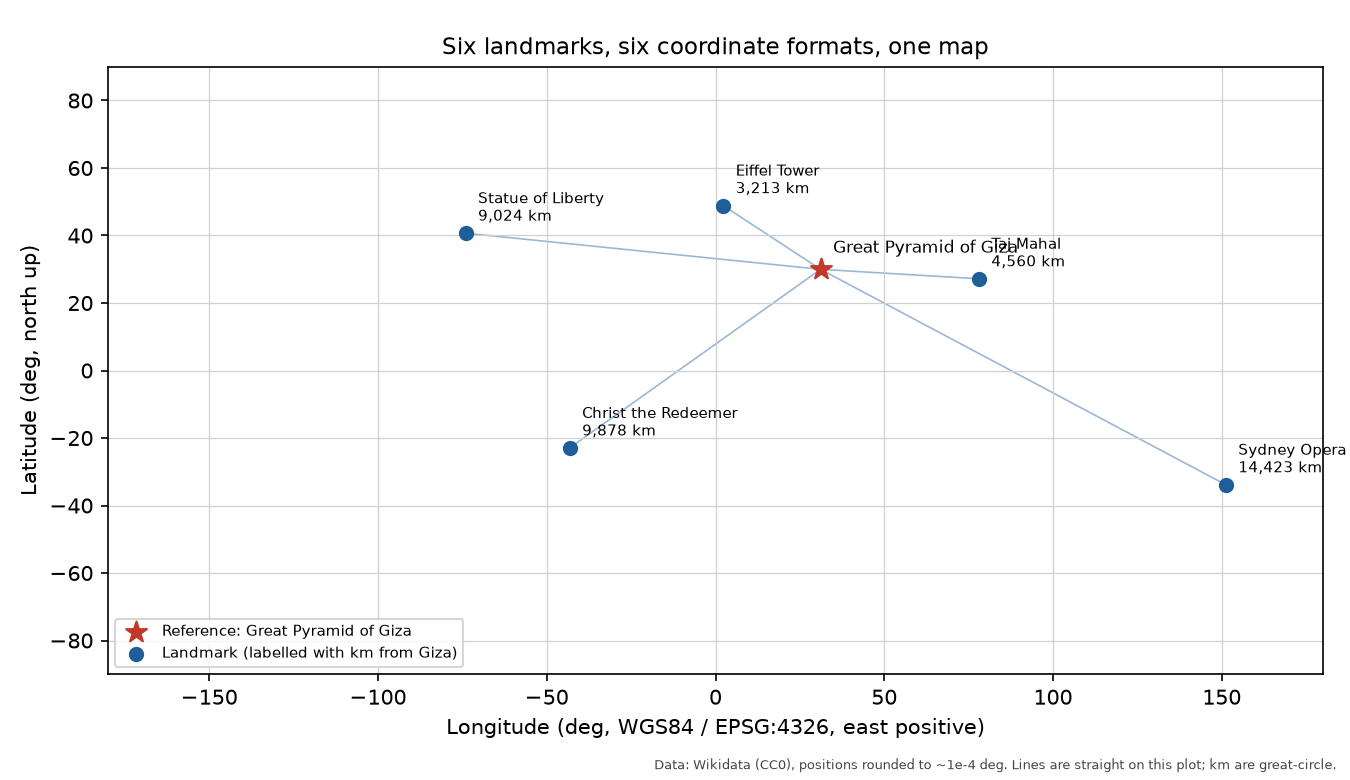

In [4]:
ms.plot(collection, 'notebook_map.png')
import os
from IPython.display import Image, display
display(Image('notebook_map.png'))
os.remove('notebook_map.png')